In [96]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from astropy.coordinates import TEME, EarthLocation
import astropy.units as u
from astropy.time import Time
from poliastro.bodies import Earth
from poliastro.constants import GM_earth, rho0_earth
from poliastro.twobody import Orbit
from poliastro.twobody.propagation import CowellPropagator
from poliastro.twobody.sampling import EpochsArray
from poliastro.core.propagation import func_twobody
from poliastro.core.perturbations import J2_perturbation, atmospheric_drag_exponential
from poliastro.core.elements import rv2coe
import datetime
import pandas as pd
from tqdm import tqdm

In [54]:
SAT_ID = ['2004-047A', '2026-152A']

In [55]:
DF = {sat_id: pd.read_csv(f"data/{sat_id}.csv") for sat_id in SAT_ID}

In [74]:
def tle2kepler(tle):
    kepler = {'a'     : np.cbrt(GM_earth / (2*np.pi * tle['MEAN_MOTION']/(u.day))**2).to(u.m),
              'ecc'   : tle['ECCENTRICITY'] * u.one,
              'inc'   : tle['INCLINATION'] * u.deg,
              'raan'  : tle['RA_OF_ASC_NODE'] * u.deg,
              'argp'  : tle['ARG_OF_PERICENTER'] * u.deg,
              'nu'    : tle['MEAN_ANOMALY'] * u.deg,
              'epoch' : Time(tle['EPOCH'], format='isot', scale='utc')}
    return kepler

KEPLER = {}
for sat_id in SAT_ID:
    df = DF[sat_id]
    kepler = {elem: [] for elem in tle2kepler(df.iloc[0])}
    for i, row in df.iterrows():
        kep = tle2kepler(row)
        for elem in kepler:
            kepler[elem].append(kep[elem])
    for elem in kepler:
        kepler[elem] = type(kepler[elem][0])(kepler[elem])
    KEPLER[sat_id] = kepler

In [275]:
epochs = Time(pd.date_range(start='15-07-2026',
                            end='15-09-2026', 
                            freq="10min"), 
                            format='datetime64', scale='utc')

In [276]:
ALIGNED_KEPLER = {}
for sat_id in SAT_ID:
    kepler = KEPLER[sat_id]
    closest_kepler_idx = [np.argmin(np.abs(epoch - Time(kepler['epoch']))) for epoch in epochs]
    aligned_kepler = {elem: [] for elem in kepler}
    for elem in aligned_kepler:
        aligned_kepler[elem] = kepler[elem][closest_kepler_idx]
    ALIGNED_KEPLER[sat_id] = aligned_kepler

In [ ]:
ORBITS = {sat_id: [] for sat_id in SAT_ID}
for sat_id in SAT_ID:
    aligned_kepler = ALIGNED_KEPLER[sat_id]
    for i in range(len(epochs)):
        kep = {elem: aligned_kepler[elem][i] for elem in aligned_kepler}
        orbit = Orbit.from_classical(Earth, **kep)
        ORBITS[sat_id].append(orbit)

/home/aurelien/.pyenv/satastro/lib/python3.12/site-packages/astropy/units/decorators.py:313: UserWarning: Wrapping true anomaly to -π <= nu < π
  return_ = wrapped_function(*func_args, **func_kwargs)


In [278]:
# Define orbit propagator
def f(t0, u_, k):
    """Function to propagate the orbit using the two-body problem."""
    # Keplerian orbit
    du_kep = func_twobody(t0, u_, k)
    # # J2 perturbation
    # ax, ay, az = J2_perturbation(t0, u_, k, J2 = Earth.J2.value, R = Earth.R.to_value(u.km))
    # du_J2 = np.array([0, 0, 0, ax, ay, az])
    # # Atmospheric drag
    # ax, ay, az = atmospheric_drag_exponential(t0, u_, k, 
    #     R = Earth.R.to_value(u.km), 
    #     H0 = H0_earth.to_value(u.km),
    #     rho0 = rho0_earth.to_value(u.kg / u.km**3),
    #     C_D = 2.2,
    #     A_over_m = ((4*(0.1*u.m * 0.2*u.m) + (0.1*u.m)**2) / (5*u.kg)).to_value(u.km**2/u.kg)
    #  ) 
    # du_drag = np.array([0, 0, 0, ax, ay, az])
    # Combine perturbations
    return du_kep #+ du_J2 # + du_drag 

# Detect reentry
method = CowellPropagator(f=f)

In [ ]:
R = {sat_id: [] for sat_id in SAT_ID}
V = {sat_id: [] for sat_id in SAT_ID}
for sat_id in SAT_ID:
    orbits = ORBITS[sat_id]
    for i, epoch in enumerate(tqdm(epochs)):
        r, v = orbits[i].to_ephem(EpochsArray(Time([epochs[i]]), method=method)).rv()
        R[sat_id].append(r[0])
        V[sat_id].append(v[0])
    R[sat_id] = u.Quantity(R[sat_id])
    V[sat_id] = u.Quantity(V[sat_id])

  0%|          | 0/8929 [00:00<?, ?it/s]

100%|██████████| 8929/8929 [05:33<00:00, 26.80it/s] 


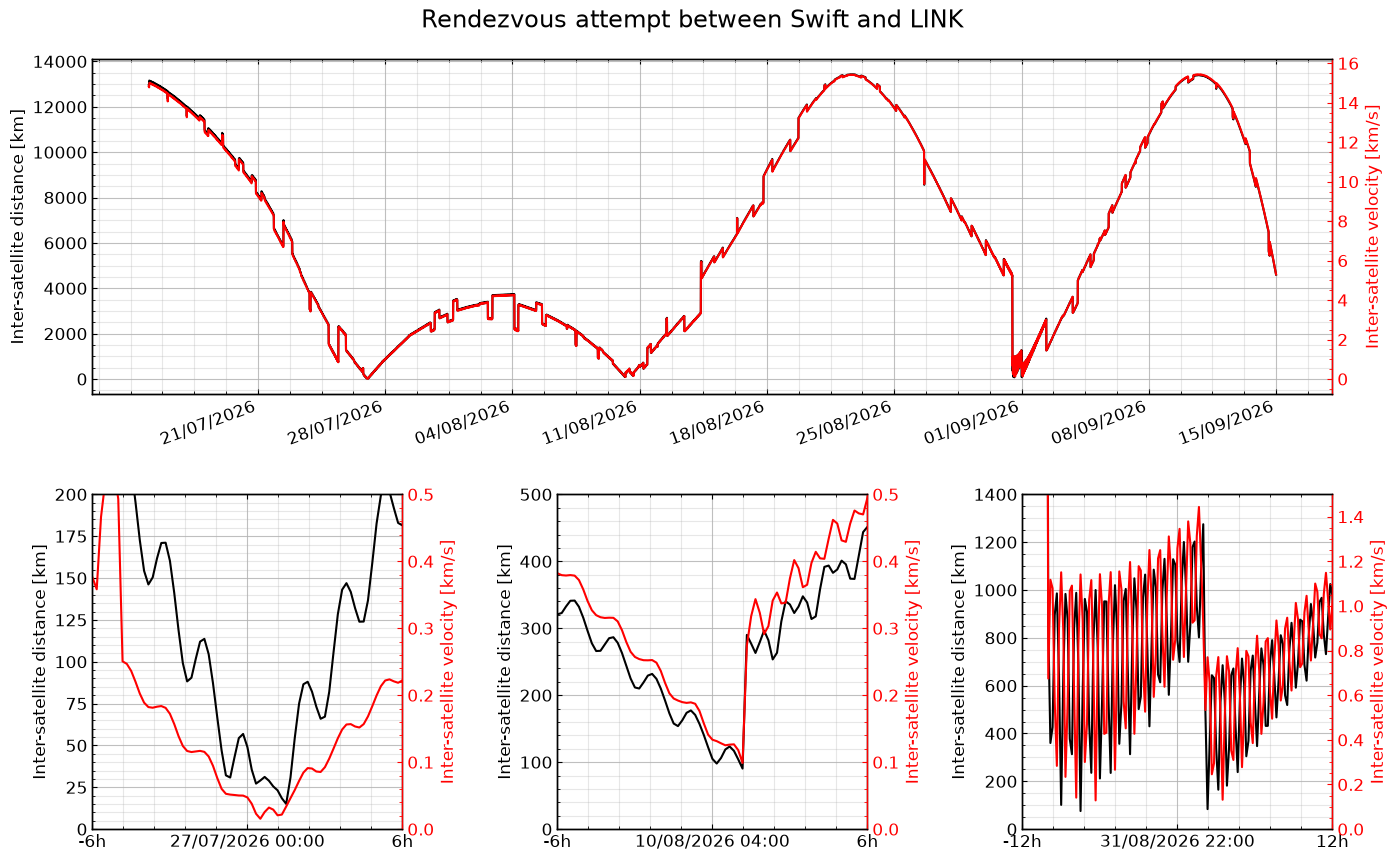

In [288]:
# fig, ax_r = plt.subplots(figsize=(16,6))
fig = plt.figure(figsize=(16,10))
gs = fig.add_gridspec(2,3, hspace=0.3, wspace=0.5)

def plot_diff(ax_r, datecenter=None, datespan=None, rlim=None, vlim=None):

    ax_v = ax_r.twinx()

    ax_r.plot(epochs.datetime, np.linalg.norm(R[SAT_ID[0]] - R[SAT_ID[1]], axis=1), c='k')
    ax_v.plot(epochs.datetime, np.linalg.norm(V[SAT_ID[0]] - V[SAT_ID[1]], axis=1), c='r')

    ax_r.set_ylabel("Inter-satellite distance [km]")
    ax_v.set_ylabel("Inter-satellite velocity [km/s]")

    if rlim is not None: ax_r.set_ylim(0, rlim)
    if vlim is not None: ax_v.set_ylim(0, vlim)
    if datecenter is not None:
        datecenter = pd.to_datetime(datecenter, dayfirst=True)
        datespan = pd.to_timedelta(datespan)
        ax_r.set_xlim(datecenter-datespan/2, datecenter+datespan/2)
        ax_r.set_xticks([datecenter-datespan/2, datecenter, datecenter+datespan/2])
        ax_r.set_xticklabels([f"{-datespan.value/1e9/3600/2:.0f}h", datecenter.strftime('%d/%m/%Y %H:%M'), f"{datespan.value/1e9/3600/2:.0f}h"], rotation=0, ha='center')
    else:
        ax_r.xaxis.set_major_locator(mdates.DayLocator(interval=7))
        ax_r.set_xticks(ax_r.get_xticks()[1::1])
        ax_r.set_xticklabels(ax_r.get_xticklabels(), rotation=20, ha='right')
        ax_r.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m/%Y'))

    ax_r.grid()
    ax_r.grid(which='minor', alpha=0.3)

    ax_v.yaxis.label.set_color('r')
    ax_v.tick_params(axis='y', which='both', colors='r')
    ax_v.spines['right'].set_edgecolor('r')

plot_diff(fig.add_subplot(gs[0,:]))
plot_diff(fig.add_subplot(gs[1,0]), rlim=200, vlim=0.5, datecenter='27/07/2026 00:00', datespan='12h')
plot_diff(fig.add_subplot(gs[1,1]), rlim=500, vlim=0.5, datecenter='10/08/2026 04:00', datespan='12h')
plot_diff(fig.add_subplot(gs[1,2]), rlim=1400, vlim=1.5, datecenter='31/08/2026 22:00', datespan='24h')

fig.suptitle("Rendezvous attempt between Swift and LINK", fontsize='xx-large', y=0.93)

plt.show()

In [284]:
print(f"Minimal distance: {np.min(np.linalg.norm(R[SAT_ID[0]] - R[SAT_ID[1]], axis=1)):.2f}")
print(f"Minimal velocity: {np.min(np.linalg.norm(V[SAT_ID[0]] - V[SAT_ID[1]], axis=1)).to(u.m/u.s):.2f}")

Minimal distance: 15.08 km
Minimal velocity: 15.46 m / s
